# 03 - Monte Carlo validation of the daily variance estimators

Chapter 2 checks the daily variance estimators from `estimators.py` on simulated data, where the true variance is known.

## Model

`simulate_ohlc` draws an intraday Brownian motion in log price with daily volatility $\sigma$ and no drift. Each day is split into $M$ equal steps of length $\Delta t = 1/M$:

$$\ln S_{t,k} = \ln S_{t,k-1} + \sigma\sqrt{\Delta t}\,Z_{t,k}, \qquad Z_{t,k} \sim \mathcal N(0,1),\quad k = 1,\dots,M.$$

There is no overnight gap: each day's open equals the previous day's close. High and Low are the max and min over the open and the $M$ intraday points, so the path is only *observed* at $M+1$ points per day. The true daily variance is $\sigma^2$ for every $M$.

## Metrics

For each estimator $\hat\sigma^2$ (cc, Parkinson, Garman-Klass), computed over $N$ simulated days:

- **Bias ratio** $= \dfrac{E[\hat\sigma^2]}{\sigma^2}$. An unbiased estimator gives 1.
- **Raw efficiency** $= \dfrac{\operatorname{Var}[\hat\sigma^2_{cc}]}{\operatorname{Var}[\hat\sigma^2]}$. How much smaller the estimator's variance is than close-to-close's.
- **Fair efficiency** $= \dfrac{\operatorname{Var}[\hat\sigma^2_{cc}] / E[\hat\sigma^2_{cc}]^2}{\operatorname{Var}[\hat\sigma^2] / E[\hat\sigma^2]^2}$. The same ratio on squared coefficients of variation, so an estimator does not look more efficient just because it is biased towards zero.

## Theory

For a continuously observed Brownian path ($M \to \infty$) with zero drift:

- close-to-close is unbiased, with $\operatorname{Var}[r^2] = 2\sigma^4$;
- Parkinson and Garman-Klass are unbiased;
- relative to close-to-close, Parkinson has efficiency $\approx 5.2$ and Garman-Klass $\approx 7.4$.

With finite $M$ the observed high is below the true high and the observed low above the true low, so the range is too small and both range estimators should be biased low. This notebook measures how large that effect is and how fast it disappears as $M$ grows.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../src")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from volforecast.simulate import simulate_ohlc
from volforecast.estimators import close_to_close, parkinson, garman_klass

In [2]:
sigma = 0.01
N = 20_000
Ms = [5, 10, 50, 100, 500, 1000]
SEED = 0

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## Experiment

The loop over $M$ is wrapped in `run_experiment(Ms, n_days, seed)` so it can be re-run for other seeds and sample sizes. The first simulated day has no previous close, so cc is NaN there; `.dropna()` removes that row so all three estimators use the same $N-1$ days.

In [3]:
def run_experiment(Ms, n_days, seed):
    """Bias ratio, raw efficiency and fair efficiency for each M, indexed by (M, estimator)."""
    tables = []
    for M in Ms:
        ohlc = simulate_ohlc(sigma=sigma, n_days=n_days, steps_per_day=M, seed=seed)
        est = pd.DataFrame({"cc": close_to_close(ohlc), "parkinson": parkinson(ohlc), "garman_klass": garman_klass(ohlc)}).dropna()
        bias_ratio = est.mean() / sigma**2
        raw_efficiency = est.var()["cc"] / est.var()
        fair_efficiency = (est.var()["cc"] / est.mean()["cc"]**2) / (est.var() / est.mean()**2)
        df = pd.DataFrame({"bias-ratio": bias_ratio, "raw-efficiency": raw_efficiency, "fair-efficiency": fair_efficiency})
        tables.append(df)
    return pd.concat(tables, keys=Ms, names=["M", "estimator"])

In [4]:
results = run_experiment(Ms, N, SEED)
results.round(3)

bias-ratio  raw-efficiency  fair-efficiency
M    estimator                                                
5    cc                 0.996           1.000            1.000
     parkinson          0.572           7.188            2.371
     garman_klass       0.408          17.550            2.949
10   cc                 0.995           1.000            1.000
     parkinson          0.663           6.851            3.045
     garman_klass       0.535          14.215            4.113
50   cc                 1.001           1.000            1.000
     parkinson          0.829           5.806            3.987
     garman_klass       0.763           9.834            5.716
100  cc                 1.011           1.000            1.000
     parkinson          0.879           5.474            4.143
     garman_klass       0.829           9.007            6.051
500  cc                 0.991           1.000            1.000
     parkinson          0.934           5.197            4.617
     garman_klass       0.912           8.105            6.865
1000 cc                 0.996           1.000            1.000
     parkinson          0.953           5.214            4.772
     garman_klass       0.936           8.143            7.195

## Bias and efficiency against M

Left: bias ratio, with the unbiased level 1. Right: fair efficiency, with the continuous-path values 5.2 (Parkinson) and 7.4 (Garman-Klass). The x-axis is logarithmic in $M$.

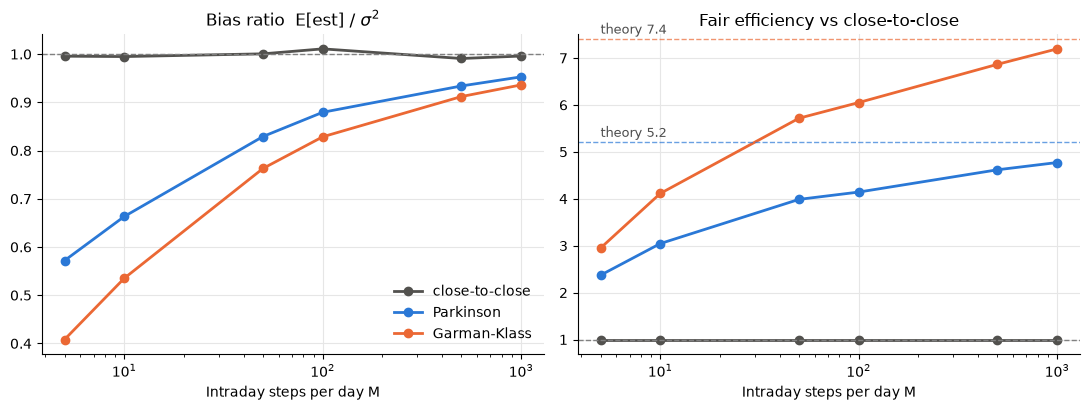

In [5]:
COLORS = {"cc": "#52514e", "parkinson": "#2a78d6", "garman_klass": "#eb6834"}
LABELS = {"cc": "close-to-close", "parkinson": "Parkinson", "garman_klass": "Garman-Klass"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name in ["cc", "parkinson", "garman_klass"]:
    sub = results.xs(name, level="estimator")
    for ax, col in zip(axes, ["bias-ratio", "fair-efficiency"]):
        ax.plot(sub.index, sub[col], marker="o", lw=2, ms=6, color=COLORS[name], label=LABELS[name])

axes[0].axhline(1, color="0.5", ls="--", lw=1)
axes[0].set_title(r"Bias ratio  E[est] / $\sigma^2$")
axes[1].axhline(1, color="0.5", ls="--", lw=1)
for level, name in [(5.2, "parkinson"), (7.4, "garman_klass")]:
    axes[1].axhline(level, color=COLORS[name], ls="--", lw=1, alpha=0.7)
    axes[1].annotate(f"theory {level}", (Ms[0], level), xytext=(0, 4), textcoords="offset points",
                     color="0.3", fontsize=9)
axes[1].set_title("Fair efficiency vs close-to-close")

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Intraday steps per day M")
    ax.grid(True, which="major", color="0.9")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "mc_bias_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

## Discretization bias

Broadie, Glasserman and Kou (1997) show that the maximum of a Brownian motion observed on a grid of step $\Delta t$ falls short of the continuous maximum by about $\beta\sigma\sqrt{\Delta t}$, with

$$\beta = -\frac{\zeta(1/2)}{\sqrt{2\pi}} \approx 0.5826.$$

By symmetry the same holds for the minimum. With $\Delta t = 1/M$ the observed range is about the true range minus $2\beta\sigma/\sqrt M$. Squaring and taking expectations, the leading correction to $E[\ln(H/L)^2]$ is of order $M^{-1/2}$, so for Parkinson and Garman-Klass

$$1 - \text{bias ratio} \;\propto\; M^{-1/2}.$$

On a log-log plot, the gap $1 - \text{bias ratio}$ against $M$ should be a straight line with slope $-1/2$. Below, the gap is averaged over 5 seeds for $M \in \{50, 100, 200, 500, 1000\}$ and the slope is fitted with `np.polyfit`.

In [6]:
from scipy.special import zeta

beta = -zeta(0.5) / np.sqrt(2 * np.pi)
print(f"beta = {beta:.4f}")

M_fit = [50, 100, 200, 500, 1000]
fit_seeds = list(range(5))
gap = pd.concat(
    [1 - run_experiment(M_fit, N, s)["bias-ratio"].unstack() for s in fit_seeds],
    keys=fit_seeds, names=["seed", "M"],
).groupby(level="M").mean()

slopes = {}
for name in ["parkinson", "garman_klass"]:
    slopes[name], _ = np.polyfit(np.log(gap.index), np.log(gap[name]), 1)
    print(f"{LABELS[name]:>13}: fitted slope = {slopes[name]:.3f}")
gap[["parkinson", "garman_klass"]].round(4)

beta = 0.5826
    Parkinson: fitted slope = -0.479
 Garman-Klass: fitted slope = -0.465


estimator,parkinson,garman_klass
M,,
50,0.1708,0.2364
100,0.1236,0.1727
200,0.0885,0.1241
500,0.0594,0.0829
1000,0.0399,0.0583


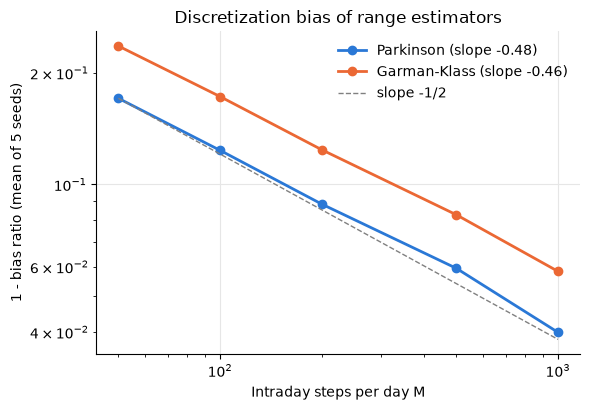

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for name in ["parkinson", "garman_klass"]:
    ax.plot(gap.index, gap[name], marker="o", lw=2, ms=6, color=COLORS[name],
            label=f"{LABELS[name]} (slope {slopes[name]:.2f})")

# Slope -1/2 reference line, anchored at the first Parkinson point.
M_ref = np.array([M_fit[0], M_fit[-1]])
ax.plot(M_ref, gap["parkinson"].iloc[0] * (M_ref / M_ref[0]) ** -0.5, color="0.5", ls="--", lw=1,
        label="slope -1/2")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Intraday steps per day M")
ax.set_ylabel("1 - bias ratio (mean of 5 seeds)")
ax.set_title("Discretization bias of range estimators")
ax.grid(True, which="major", color="0.9")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "mc_bias_slope.png", dpi=150, bbox_inches="tight")
plt.show()

### Why a single seed over all M gives a flatter slope

Fitting the same regression to the single-seed results above, over all $M$ from 5 to 1000, gives a less steep slope (about $-0.42$). Two things pull it away from $-1/2$:

- **Small $M$ is pre-asymptotic.** The $M^{-1/2}$ law is only the leading term. At $M = 5$ or $10$ the gap is 30-60% and higher-order terms matter, so those points lie below the extrapolated line and flatten the fit.
- **The gap is noisy when it is small.** At large $M$ the gap is only a few percent, while the sampling error of the mean is about $\sqrt{2/N} \approx 1\%$ for close-to-close (smaller for the range estimators, but not negligible). On a log scale, an error of that size on a gap of 4-5% moves the point a lot. Averaging over seeds reduces this noise, and starting at $M = 50$ drops the pre-asymptotic points.

In [8]:
gap_single = 1 - results["bias-ratio"].unstack()
for name in ["parkinson", "garman_klass"]:
    s, _ = np.polyfit(np.log(gap_single.index), np.log(gap_single[name]), 1)
    print(f"{LABELS[name]:>13}: seed {SEED}, M = {Ms[0]}..{Ms[-1]}: slope = {s:.3f}")

    Parkinson: seed 0, M = 5..1000: slope = -0.417
 Garman-Klass: seed 0, M = 5..1000: slope = -0.423


## Robustness

Two checks that the numbers above are not an artefact of one random draw:

1. the same experiment for seeds 0, 1 and 2 at $M \in \{10, 100, 1000\}$;
2. fair efficiency with $N = 20{,}000$ against $N = 100{,}000$ days at $M \in \{10, 100\}$.

In [9]:
seeds = [0, 1, 2]
by_seed = pd.concat([run_experiment([10, 100, 1000], N, s) for s in seeds], keys=seeds, names=["seed"])
by_seed[["bias-ratio", "fair-efficiency"]].unstack("seed").round(3)

bias-ratio               fair-efficiency              
seed                       0      1      2               0      1      2
M    estimator                                                          
10   cc                0.995  0.980  1.005           1.000  1.000  1.000
     parkinson         0.663  0.655  0.667           3.045  2.938  2.969
     garman_klass      0.535  0.530  0.536           4.113  3.812  4.042
100  cc                1.011  1.018  0.993           1.000  1.000  1.000
     parkinson         0.879  0.878  0.875           4.143  4.144  4.299
     garman_klass      0.829  0.824  0.829           6.051  6.049  6.455
1000 cc                0.996  1.017  1.010           1.000  1.000  1.000
     parkinson         0.953  0.960  0.960           4.772  4.551  4.653
     garman_klass      0.936  0.938  0.941           7.195  6.852  7.002

In [10]:
by_n = pd.concat(
    [run_experiment([10, 100], n, SEED)["fair-efficiency"] for n in [20_000, 100_000]],
    axis=1, keys=["N=20,000", "N=100,000"],
)
by_n.round(3)

N=20,000  N=100,000
M   estimator                        
10  cc               1.000      1.000
    parkinson        3.045      2.980
    garman_klass     4.113      3.953
100 cc               1.000      1.000
    parkinson        4.143      4.268
    garman_klass     6.051      6.191

## Conclusions

- Close-to-close is unbiased at every M. Its bias ratio is between 0.991 and 1.011 for seed 0 (0.980 to 1.018 across seeds 0-2) which is well within the sampling error of sqrt(2/N) ~ 1% (at most two standard errors). It only uses closes so it's not dependent on how often the path is seen during the day.
- The range estimators are biased low and the degree of bias diminishes very slowly. At M=5 the bias ratios are 0.572 (Parkinson) and 0.408 (Garman-Klass); at M=1000 they are still 0.953 and 0.936 respectively. Garman-Klass is always more biased than Parkinson. The range term in GK has expectation 2ln2σ² 1.386σ² and it subtracts an unbiased open-to-close term of value 0.386σ² so 1-biasgk = 2ln2 (1-biasp). At M=5: 1.386 x 0.428 = 0.593, i.e. a bias ratio of 0.407, which matches the simulation.
- The bias decays as predicted by Broadie-Glasserman-Kou, like $M^{-1/2}$. Over 5 seeds for $M = 50$ to $1000$, the fitted log-log slope of $1 - \text{bias ratio}$ is -0.479 for Parkinson and -0.465 for Garman-Klass (very close to-1/2). A single seed over the full range of $M$ from 5 to 1000 gives -0.417 and -0.423 respectively. The small-$m$ pre-asymptotic behaviour and the noise in the small gaps at large $M$ are both responsible for the flattening.
- Raw efficiency is a very misleading measure for biased estimators. An estimator which is shrunk towards zero will have a lower variance for that very reason. At M=5 Garman-Klass has a raw efficiency of 17.5 (a lot higher than the theoretical 7.4) but its fair efficiency is only 2.9. At M=1000 the raw efficiencies (5.21 and 8.14) are still way above the fair efficiencies.
- Fair efficiency approaches the theory from below. It increases with M, reaching 4.77 for Parkinson and 7.20 for Garman-Klass at M = 1000, against the continuous path values of 5.2 and 7.4 respectively. A discretely observed range contains less information than the true range so the improvement over close-to-close is less than the textbook figure.
- The results are stable. Across seeds 0, 1 and 2 the range estimator bias ratios vary by less than 0.01 at each M and fair efficiencies vary by about +/- 5% (e.g. Garman-Klass 6.85 to 7.20 at M=1000). The change from N=20,000 to N=100,000 results in a change in fair efficiency of 2-4% (Garman-Klass 4.11 to 3.95 at M=10, 6.05 to 6.19 at M=100) in either direction so the remaining differences are just sampling noise rather than a trend in N.
- Implication for real data: real prices are only observed at discrete trades so the daily High and Low will be less than the true range and Parkinson and Garman-Klass will be less than the true volatility. The less trades per day the greater the effect. For an illiquid asset (FXE in its early days being a good example) the effective M is very small and the range estimators can be biased low by tens of percent. When you're comparing range based and close to close volatility across assets part of the gap may simply be due to this discretisation bias rather than any actual difference in the underlying volatility.